In [3]:
"""
教學範例：交叉式 Gage R&R + SPC 製程能力分析

資料為程式產生的模擬數據，不能當成實際量產結論。
設計：10 個零件 × 3 位作業員 × 2 次重複量測
製程：25 個子組 × 每組 4 件
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm


# -----------------------------
# 設定：可依實際案例修改
# -----------------------------
SEED = 2026
LSL = 19.900
USL = 20.100
TARGET = 20.000

N_PARTS = 10
N_OPERATORS = 3
N_REPEATS = 2

N_SUBGROUPS = 25
SUBGROUP_SIZE = 4

rng = np.random.default_rng(SEED)


In [5]:
# =========================================================
# A. 產生交叉式 MSA（Gage R&R）模擬資料
# =========================================================
parts = [f"P{i:02d}" for i in range(1, N_PARTS + 1)]
operators = ["A", "B", "C"]

# 零件真值刻意分布在製程範圍內，以呈現零件間差異
part_true = dict(zip(parts, np.linspace(19.930, 20.070, N_PARTS)))

# 模擬作業員間的小幅平均差異
operator_effect = {"A": -0.0010, "B": 0.0000, "C": 0.0010}

# 模擬 Part × Operator 交互作用
interaction_effect = {
    (part, operator): rng.normal(0, 0.0007)
    for part in parts
    for operator in operators
}

msa_rows = []
for part in parts:
    for operator in operators:
        for repeat in range(1, N_REPEATS + 1):
            measured = (
                part_true[part]
                + operator_effect[operator]
                + interaction_effect[(part, operator)]
                + rng.normal(0, 0.0012)  # 重複性誤差
            )
            msa_rows.append(
                {
                    "part": part,
                    "operator": operator,
                    "repeat": repeat,
                    "measurement": measured,
                }
            )

msa = pd.DataFrame(msa_rows)

# 模擬量測順序隨機化
msa = msa.sample(frac=1, random_state=SEED).reset_index(drop=True)
msa["run_order"] = np.arange(1, len(msa) + 1)
msa.to_csv("msa_synthetic_data.csv", index=False)



In [6]:
msa

,part,operator,repeat,measurement,run_order
0,P08,C,1,20.039601,1
1,P03,B,1,19.962037,2
2,P04,A,2,19.979290,3
3,P06,A,2,20.005144,4
4,P09,A,2,20.053681,5
5,P02,C,2,19.945598,6
6,P02,C,1,19.946596,7
7,P03,C,1,19.964544,8
8,P04,A,1,19.978580,9
9,P04,C,2,19.979220,10


In [8]:
# =========================================================
# B. 交叉式 Gage R&R：ANOVA 及變異成分
# =========================================================
# 平衡交叉設計：part、operator 及其交互作用
model = smf.ols(
    "measurement ~ C(part) * C(operator)",
    data=msa
).fit()

anova_table = anova_lm(model, typ=2)

# statsmodels 沒有直接輸出 mean_sq，需自行計算：均方 = 平方和 / 自由度
anova_table["mean_sq"] = anova_table["sum_sq"] / anova_table["df"]

ms_part = anova_table.loc["C(part)", "mean_sq"]
ms_operator = anova_table.loc["C(operator)", "mean_sq"]
ms_interaction = anova_table.loc["C(part):C(operator)", "mean_sq"]
ms_repeatability = anova_table.loc["Residual", "mean_sq"]

# 平衡交叉 ANOVA 的方法矩估計；負值截為 0
var_repeatability = max(ms_repeatability, 0.0)
var_part_operator = max(
    (ms_interaction - ms_repeatability) / N_REPEATS,
    0.0
)
var_operator = max(
    (ms_operator - ms_interaction) / (N_PARTS * N_REPEATS),
    0.0
)
var_part = max(
    (ms_part - ms_interaction) / (N_OPERATORS * N_REPEATS),
    0.0
)

var_reproducibility = var_operator + var_part_operator
var_grr = var_repeatability + var_reproducibility
var_total = var_grr + var_part

sd_repeatability = np.sqrt(var_repeatability)
sd_operator = np.sqrt(var_operator)
sd_interaction = np.sqrt(var_part_operator)
sd_grr = np.sqrt(var_grr)
sd_part = np.sqrt(var_part)
sd_total = np.sqrt(var_total)

tolerance = USL - LSL

pct_study_grr = (
    100 * sd_grr / sd_total if sd_total > 0 else np.nan
)
pct_tolerance_grr = (
    100 * 6 * sd_grr / tolerance if tolerance > 0 else np.nan
)
ndc = (
    int(np.floor(1.41 * sd_part / sd_grr))
    if sd_grr > 0 else np.inf
)

if pct_tolerance_grr < 10 and ndc >= 5:
    msa_judgment = "一般可接受（此處為課堂判讀規則）"
elif pct_tolerance_grr <= 30 and ndc >= 5:
    msa_judgment = "有條件使用；應評估用途與風險"
else:
    msa_judgment = "不建議直接發布製程能力結論；先檢討量測系統"


In [10]:
pct_study_grr

np.float64(3.122876659596603)

In [11]:
# =========================================================
# C. 產生製程能力分析用的子組資料
# =========================================================
# 模擬穩定、近似常態的製程資料
process_values = rng.normal(
    loc=20.010,
    scale=0.018,
    size=(N_SUBGROUPS, SUBGROUP_SIZE)
)

process_rows = []
for subgroup_index, row in enumerate(process_values, start=1):
    for within_index, value in enumerate(row, start=1):
        process_rows.append(
            {
                "subgroup": subgroup_index,
                "within_subgroup": within_index,
                "measurement": value,
            }
        )

process = pd.DataFrame(process_rows)
process.to_csv("process_synthetic_data.csv", index=False)

# \bar{X}-R 管制圖統計量（n=4 常數）
subgroup_summary = (
    process.groupby("subgroup")["measurement"]
    .agg(xbar="mean", range=lambda x: x.max() - x.min())
    .reset_index()
)

xbarbar = subgroup_summary["xbar"].mean()
rbar = subgroup_summary["range"].mean()

A2 = 0.729
D3 = 0.000
D4 = 2.282
d2 = 2.059

xbar_ucl = xbarbar + A2 * rbar
xbar_lcl = xbarbar - A2 * rbar
r_ucl = D4 * rbar
r_lcl = D3 * rbar

xbar_in_control = (
    (subgroup_summary["xbar"] <= xbar_ucl)
    & (subgroup_summary["xbar"] >= xbar_lcl)
).all()

r_in_control = (
    (subgroup_summary["range"] <= r_ucl)
    & (subgroup_summary["range"] >= r_lcl)
).all()

stable_by_3sigma = bool(xbar_in_control and r_in_control)

# 組內標準差估計：R-bar / d2
sigma_within = rbar / d2

# 整體標準差：全部觀測值的樣本標準差
overall_mean = process["measurement"].mean()
sigma_overall = process["measurement"].std(ddof=1)

# 常態假設下的能力指標
cp = (USL - LSL) / (6 * sigma_within)
cpu = (USL - overall_mean) / (3 * sigma_within)
cpl = (overall_mean - LSL) / (3 * sigma_within)
cpk = min(cpu, cpl)

pp = (USL - LSL) / (6 * sigma_overall)
ppu = (USL - overall_mean) / (3 * sigma_overall)
ppl = (overall_mean - LSL) / (3 * sigma_overall)
ppk = min(ppu, ppl)

# 以下門檻只作為示範判讀，實務須依客戶／產業規範設定
msa_pass_for_demo = pct_tolerance_grr < 10 and ndc >= 5

if msa_pass_for_demo and stable_by_3sigma:
    capability_status = "可進行初步能力解讀；仍須檢查常態性、取樣設計及其他管制圖規則"
else:
    capability_status = "能力指標僅作示範計算，不宜直接作為製程放行結論"


In [12]:


# =========================================================
# D. 輸出結果
# =========================================================
print("\n========== MSA：交叉式 Gage R&R ==========")
print(f"總量測筆數             : {len(msa)}")
print(f"重複性 SD              : {sd_repeatability:.6f} mm")
print(f"作業員差異 SD          : {sd_operator:.6f} mm")
print(f"Part×Operator SD       : {sd_interaction:.6f} mm")
print(f"總 Gage R&R SD         : {sd_grr:.6f} mm")
print(f"零件間 SD              : {sd_part:.6f} mm")
print(f"%Study Variation (GRR) : {pct_study_grr:.2f}%")
print(f"%Tolerance (GRR)       : {pct_tolerance_grr:.2f}%")
print(f"ndc                    : {ndc}")
print(f"MSA 判讀               : {msa_judgment}")

print("\nANOVA 表：")
print(anova_table.round(8))

print("\n========== 製程穩定性：X-bar / R ==========")
print(f"X-bar 中心線           : {xbarbar:.5f} mm")
print(f"X-bar LCL / UCL        : {xbar_lcl:.5f} / {xbar_ucl:.5f} mm")
print(f"R-bar                  : {rbar:.5f} mm")
print(f"R LCL / UCL            : {r_lcl:.5f} / {r_ucl:.5f} mm")
print(f"三倍標準差界限檢查     : {'未發現界外點' if stable_by_3sigma else '有界外點'}")

print("\n========== 製程能力指標 ==========")
print(f"規格 LSL / USL         : {LSL:.3f} / {USL:.3f} mm")
print(f"目標 Target            : {TARGET:.3f} mm")
print(f"樣本平均               : {overall_mean:.5f} mm")
print(f"組內標準差估計         : {sigma_within:.6f} mm")
print(f"整體標準差             : {sigma_overall:.6f} mm")
print(f"Cp / Cpk               : {cp:.3f} / {cpk:.3f}")
print(f"Pp / Ppk               : {pp:.3f} / {ppk:.3f}")
print(f"解讀狀態               : {capability_status}")


========== MSA：交叉式 Gage R&R ==========
總量測筆數             : 60
重複性 SD              : 0.001216 mm
作業員差異 SD          : 0.000625 mm
Part×Operator SD       : 0.000532 mm
總 Gage R&R SD         : 0.001467 mm
零件間 SD              : 0.046948 mm
%Study Variation (GRR) : 3.12%
%Tolerance (GRR)       : 4.40%
ndc                    : 45
MSA 判讀               : 一般可接受（此處為課堂判讀規則）

ANOVA 表：
                       sum_sq    df            F    PR(>F)   mean_sq
C(part)              0.119041   9.0  8946.248739  0.000000  0.013227
C(operator)          0.000020   2.0     6.661866  0.004036  0.000010
C(part):C(operator)  0.000037  18.0     1.382707  0.210570  0.000002
Residual             0.000044  30.0          NaN       NaN  0.000001

========== 製程穩定性：X-bar / R ==========
X-bar 中心線           : 20.01127 mm
X-bar LCL / UCL        : 19.97946 / 20.04307 mm
R-bar                  : 0.04363 mm
R LCL / UCL            : 0.00000 / 0.09956 mm
三倍標準差界限檢查     : 未發現界外點

========== 製程能力指標 ==========
規格 LSL / USL         : 

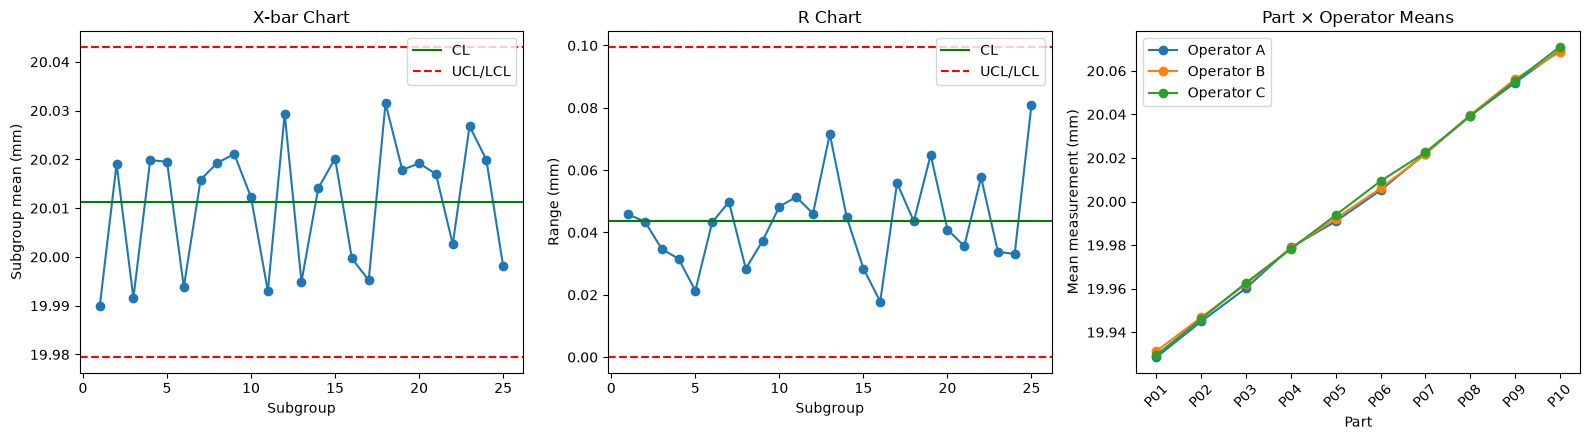


已輸出：
  msa_synthetic_data.csv
  process_synthetic_data.csv
  msa_spc_demo.png


In [13]:

# =========================================================
# E. 繪製教學圖：X-bar、R 管制圖及零件×作業員平均圖
# =========================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# X-bar chart
axes[0].plot(
    subgroup_summary["subgroup"],
    subgroup_summary["xbar"],
    marker="o"
)
axes[0].axhline(xbarbar, color="green", label="CL")
axes[0].axhline(xbar_ucl, color="red", linestyle="--", label="UCL/LCL")
axes[0].axhline(xbar_lcl, color="red", linestyle="--")
axes[0].set_title("X-bar Chart")
axes[0].set_xlabel("Subgroup")
axes[0].set_ylabel("Subgroup mean (mm)")
axes[0].legend()

# R chart
axes[1].plot(
    subgroup_summary["subgroup"],
    subgroup_summary["range"],
    marker="o"
)
axes[1].axhline(rbar, color="green", label="CL")
axes[1].axhline(r_ucl, color="red", linestyle="--", label="UCL/LCL")
axes[1].axhline(r_lcl, color="red", linestyle="--")
axes[1].set_title("R Chart")
axes[1].set_xlabel("Subgroup")
axes[1].set_ylabel("Range (mm)")
axes[1].legend()

# MSA interaction plot：各零件在不同作業員下的平均量測值
interaction_means = (
    msa.groupby(["part", "operator"])["measurement"]
    .mean()
    .unstack("operator")
)
for operator in operators:
    axes[2].plot(
        interaction_means.index,
        interaction_means[operator],
        marker="o",
        label=f"Operator {operator}"
    )
axes[2].set_title("Part × Operator Means")
axes[2].set_xlabel("Part")
axes[2].set_ylabel("Mean measurement (mm)")
axes[2].tick_params(axis="x", rotation=45)
axes[2].legend()

plt.tight_layout()
plt.savefig("msa_spc_demo.png", dpi=150)
plt.show()

print("\n已輸出：")
print("  msa_synthetic_data.csv")
print("  process_synthetic_data.csv")
print("  msa_spc_demo.png")